# Fashion-MNIST Architectures, Part 1: Linear and MLP Baselines

**Author:** Dương Nguyễn Tấn Đạt

## Problem formulation
- **Task:** single-label image classification of fashion products into 10 classes.
- **Input:** a grayscale image $x \in [0, 255]^{28 \times 28}$ (one product per image, centered on a black background).
- **Output:** a class label $\hat{y} \in \{0, \dots, 9\}$, obtained as $\hat{y} = \arg\max_k z_k$ from the logits $z = f_\theta(x) \in \mathbb{R}^{10}$.
- **Prediction unit:** one image.
- **Training objective:** minimize the mean cross-entropy $\mathcal{L}(\theta) = -\frac{1}{N}\sum_{i=1}^{N} \log \mathrm{softmax}(f_\theta(x_i))_{y_i}$.
- **Main difficulty:** several upper-body garment classes (T-shirt/top, Pullover, Coat, Shirt) share almost the same silhouette at $28 \times 28$ resolution.

## Datasets used
| Role | Dataset |
|---|---|
| Debugging | Not used |
| Main comparison | **Fashion-MNIST** (Zalando Research, MIT license, loaded via `torchvision.datasets.FashionMNIST`) |
| Extension | None |

## Pipeline
```
Raw uint8 images -> stratified split -> normalization (+ horizontal flip on train) -> Dataset / DataLoader
-> model (Linear | MLP) -> cross-entropy loss -> AdamW + cosine LR -> argmax prediction
-> checkpoint selection on validation macro-F1 -> one-time test evaluation -> metrics, curves, error analysis
```

**Scope of this notebook:** EDA, the data pipeline, the training loop and the linear and MLP baselines. The full comparison with a CNN, LSTM/GRU and Transformer is in `02_architecture_comparison.ipynb`.

> **How to run on Google Colab:** `Runtime -> Change runtime type -> T4 GPU`, then `Runtime -> Run all`. With 3 training seeds the full run takes roughly 20-30 minutes on a T4. Set `TRAIN_SEEDS = [42]` in Section 1 for a quick debugging run.

## Section 1: Reproducibility and Environment
- `SPLIT_SEED` fixes the train/validation partition. It is shared by every model, so all models see exactly the same data.
- `TRAIN_SEEDS` controls weight initialization, shuffling order and augmentation. Each model is trained once per seed so results are reported as mean ± std instead of a single lucky run.
- `set_seed` is called **right before each model is built**, so a model's initial weights do not depend on how many other models were created before it.

In [1]:
import os
import sys
import time
import json
import random
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from IPython.display import display

SPLIT_SEED = 42                  # one fixed partition for every model
TRAIN_SEEDS = [42, 123, 2026]    # independent training runs per model


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SPLIT_SEED)
# Deterministic cuDNN kernels trade a little speed for run-to-run repeatability
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ENV_INFO = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "device": str(device),
    "cuda": torch.version.cuda if torch.cuda.is_available() else None,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "gpu_memory_gb": round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2) if torch.cuda.is_available() else None,
    "split_seed": SPLIT_SEED,
    "train_seeds": TRAIN_SEEDS,
}
for k, v in ENV_INFO.items():
    print(f"{k:>14}: {v}")

FIG_DIR = "./results/figures"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs("./checkpoints", exist_ok=True)
with open("./results/environment.json", "w") as f:
    json.dump(ENV_INFO, f, indent=2)


def save_fig(name, fig=None):
    # Vector copies for the LaTeX report; the notebook still shows the figure inline
    (fig or plt.gcf()).savefig(os.path.join(FIG_DIR, f"{name}.pdf"), bbox_inches="tight")

        python: 3.12.14
         torch: 2.15.0+cpu
   torchvision: 0.29.2+cpu
         numpy: 2.5.4
  scikit-learn: 1.9.1
        device: cpu
          cuda: None
           gpu: None
 gpu_memory_gb: None
    split_seed: 42
   train_seeds: [42, 123, 2026]


## Section 2: Data Loading, Split and Leakage Checks
**Source:** Fashion-MNIST, 60,000 official training images and 10,000 official test images, $28 \times 28$ grayscale, 10 classes.

**Split policy:**
- The official **test** set is kept untouched and is evaluated only once per trained model, after checkpoint selection.
- The official training set is split into **train** (5,000 per class = 50,000) and **validation** (1,000 per class = 10,000).
- The split is **stratified by class** and uses `SPLIT_SEED`, so class proportions are identical across splits and the partition is reproducible. Split indices are saved to `results/split_indices.pt`.

**Leakage checks:**
- Train and validation indices are disjoint (asserted).
- Normalization statistics are computed from the **train split only**, so validation and test pixels never influence preprocessing.
- Exact pixel-level duplicates are detected by hashing every image. Duplicates across splits would inflate validation/test scores.

In [2]:
CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
NUM_CLASSES = len(CLASS_NAMES)
DATA_DIR = "./data"

raw_train = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)
raw_test = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True)

# Raw uint8 tensors of shape [N, 28, 28]; working on tensors avoids a PIL round-trip per sample
trainval_images, trainval_labels = raw_train.data, raw_train.targets
test_images, test_labels = raw_test.data, raw_test.targets

VAL_PER_CLASS = 1000
split_gen = torch.Generator().manual_seed(SPLIT_SEED)
train_parts, val_parts = [], []
for c in range(NUM_CLASSES):
    cls_idx = torch.nonzero(trainval_labels == c).squeeze(1)
    cls_idx = cls_idx[torch.randperm(len(cls_idx), generator=split_gen)]
    val_parts.append(cls_idx[:VAL_PER_CLASS])
    train_parts.append(cls_idx[VAL_PER_CLASS:])
train_idx = torch.cat(train_parts).sort().values
val_idx = torch.cat(val_parts).sort().values
test_idx = torch.arange(len(test_labels))

assert len(set(train_idx.tolist()) & set(val_idx.tolist())) == 0, "train/val overlap"
assert len(train_idx) + len(val_idx) == len(trainval_labels)
torch.save({"split_seed": SPLIT_SEED, "train_idx": train_idx, "val_idx": val_idx}, "./results/split_indices.pt")

print(pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Source": ["official train (stratified)", "official train (stratified)", "official test"],
    "Samples": [len(train_idx), len(val_idx), len(test_idx)],
}).to_string(index=False))

# Normalization statistics from the train split only
train_pixels = trainval_images[train_idx].float().div(255.0)
NORM_MEAN = train_pixels.mean().item()
NORM_STD = train_pixels.std().item()
del train_pixels
print(f"\nNormalization stats (train split only): mean = {NORM_MEAN:.4f}, std = {NORM_STD:.4f}")

# Exact-duplicate detection via per-image hashes
def image_hashes(images):
    return np.array([hashlib.md5(img.numpy().tobytes()).hexdigest() for img in images])

trainval_hashes = image_hashes(trainval_images)
test_hashes = image_hashes(test_images)
split_hashes = {
    "Train": trainval_hashes[train_idx.numpy()],
    "Validation": trainval_hashes[val_idx.numpy()],
    "Test": test_hashes,
}
dup_stats = {}
print("\nExact duplicate images:")
for name, h in split_hashes.items():
    dup_stats[f"within {name}"] = len(h) - len(set(h))
    print(f"  within {name:<10}: {dup_stats[f'within {name}']}")
for a, b in [("Train", "Validation"), ("Train", "Test"), ("Validation", "Test")]:
    dup_stats[f"{b} in {a}"] = int(np.isin(split_hashes[b], split_hashes[a]).sum())
    print(f"  {b} images whose exact copy is in {a}: {dup_stats[f'{b} in {a}']}")

     Split                      Source  Samples
     Train official train (stratified)    50000
Validation official train (stratified)    10000
      Test               official test    10000

Normalization stats (train split only): mean = 0.2862, std = 0.3531



Exact duplicate images:
  within Train     : 0
  within Validation: 0
  within Test      : 0
  Validation images whose exact copy is in Train: 0
  Test images whose exact copy is in Train: 0
  Test images whose exact copy is in Validation: 0


## Section 3: Exploratory Data Analysis
The analysis covers class distribution, input size, imbalance and representative samples. We also inspect pixel statistics, because several of the models see raw flattened pixels and nothing else.

Image tensor shape : (28, 28) (H x W), 1 channel, dtype torch.uint8
Flattened dim      : 784 features per image
Pixel value range  : [0, 255]
Background pixels  : 50.2% of all train/val pixels are exactly 0
On-disk size       : 81.9 MB (raw IDX files + archives in ./data)

Samples per class:


,Train,Validation,Test
T-shirt/top,5000,1000,1000
Trouser,5000,1000,1000
Pullover,5000,1000,1000
Dress,5000,1000,1000
Coat,5000,1000,1000
Sandal,5000,1000,1000
Shirt,5000,1000,1000
Sneaker,5000,1000,1000
Bag,5000,1000,1000
Ankle boot,5000,1000,1000


Train         1.0
Validation    1.0
Test          1.0


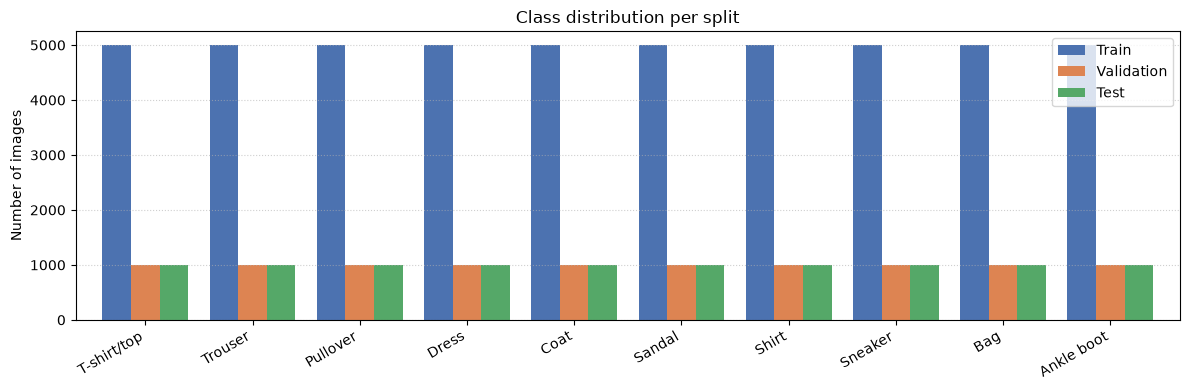

In [3]:
# 3.1 Input size and value range
sample = trainval_images[0]
print(f"Image tensor shape : {tuple(sample.shape)} (H x W), 1 channel, dtype {sample.dtype}")
print(f"Flattened dim      : {sample.numel()} features per image")
print(f"Pixel value range  : [{trainval_images.min().item()}, {trainval_images.max().item()}]")
background_pct = (trainval_images == 0).float().mean().item() * 100
print(f"Background pixels  : {background_pct:.1f}% of all train/val pixels are exactly 0")
storage_mb = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(DATA_DIR) for f in fs) / 1024**2
print(f"On-disk size       : {storage_mb:.1f} MB (raw IDX files + archives in {DATA_DIR})")

# 3.2 Class distribution per split and imbalance ratio
dist = pd.DataFrame({
    "Train": np.bincount(trainval_labels[train_idx].numpy(), minlength=NUM_CLASSES),
    "Validation": np.bincount(trainval_labels[val_idx].numpy(), minlength=NUM_CLASSES),
    "Test": np.bincount(test_labels.numpy(), minlength=NUM_CLASSES),
}, index=CLASS_NAMES)
print("\nSamples per class:")
display(dist)
imbalance = (dist.max() / dist.min()).rename("Imbalance ratio (max/min)")
print(imbalance.to_string())

ax = dist.plot(kind="bar", figsize=(12, 4), width=0.8, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_title("Class distribution per split")
ax.set_ylabel("Number of images")
ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
ax.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
save_fig("eda_class_distribution")
plt.show()

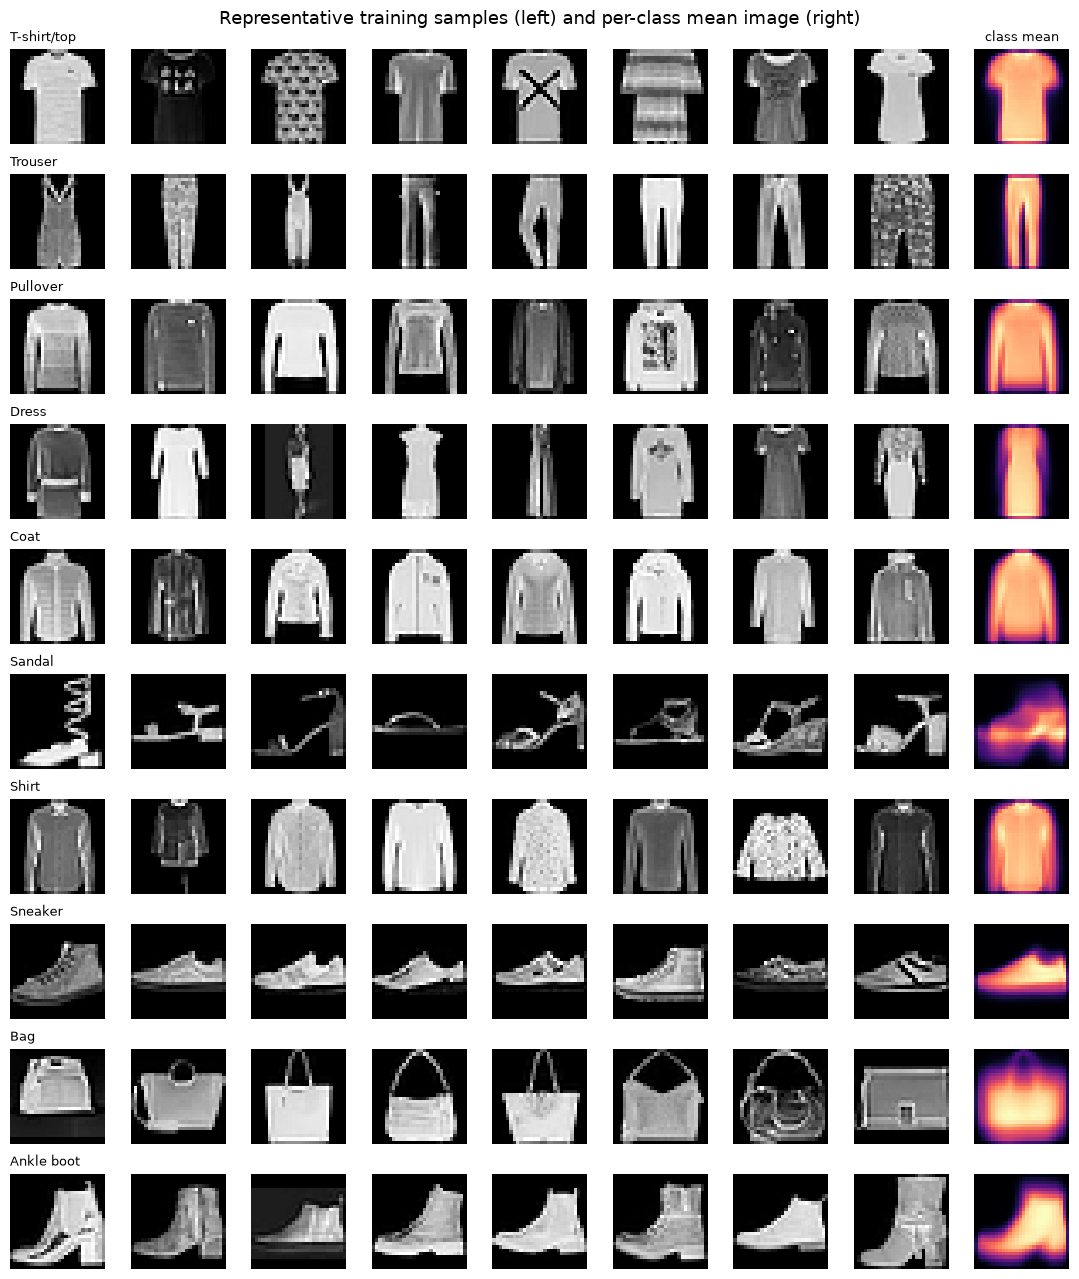

In [4]:
# 3.3 Representative samples (8 random training images per class) and the per-class mean image
samples_per_class = 8
eda_gen = torch.Generator().manual_seed(SPLIT_SEED)
train_labels_split = trainval_labels[train_idx]

fig, axes = plt.subplots(NUM_CLASSES, samples_per_class + 1, figsize=(11, 13))
for c in range(NUM_CLASSES):
    cls_pool = train_idx[train_labels_split == c]
    picks = cls_pool[torch.randperm(len(cls_pool), generator=eda_gen)[:samples_per_class]]
    for j, idx in enumerate(picks):
        axes[c, j].imshow(trainval_images[idx], cmap="gray")
        axes[c, j].axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], fontsize=9, loc="left")
    mean_img = trainval_images[cls_pool].float().mean(0)
    axes[c, -1].imshow(mean_img, cmap="magma")
    axes[c, -1].axis("off")
axes[0, -1].set_title("class mean", fontsize=9)
plt.suptitle("Representative training samples (left) and per-class mean image (right)", fontsize=13)
plt.tight_layout()
save_fig("eda_samples")
plt.show()

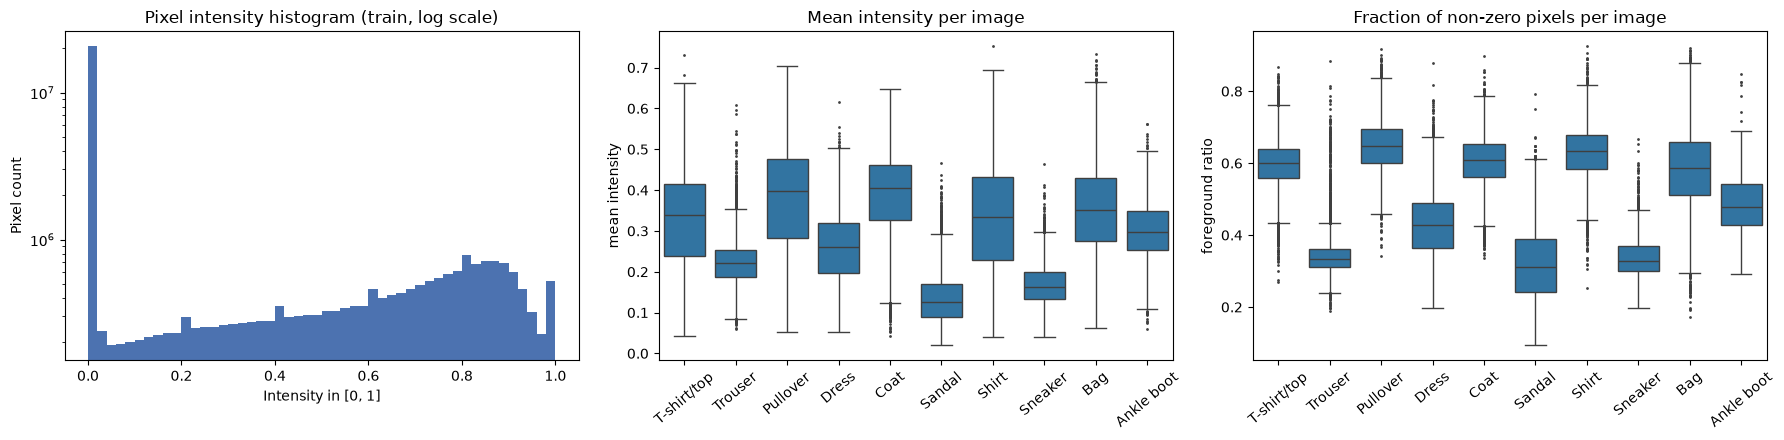

             mean intensity  foreground ratio
class                                        
T-shirt/top           0.340             0.601
Trouser               0.221             0.333
Pullover              0.398             0.647
Dress                 0.260             0.427
Coat                  0.404             0.608
Sandal                0.125             0.312
Shirt                 0.335             0.634
Sneaker               0.163             0.329
Bag                   0.352             0.587
Ankle boot            0.297             0.477


In [5]:
# 3.4 Pixel statistics: global intensity histogram and per-class image statistics
train_imgs_float = trainval_images[train_idx].float() / 255.0
per_image = pd.DataFrame({
    "class": [CLASS_NAMES[i] for i in train_labels_split.tolist()],
    "mean intensity": train_imgs_float.mean(dim=(1, 2)).numpy(),
    "foreground ratio": (train_imgs_float > 0).float().mean(dim=(1, 2)).numpy(),
})

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].hist(train_imgs_float.flatten().numpy(), bins=50, color="#4C72B0", log=True)
axes[0].set_title("Pixel intensity histogram (train, log scale)")
axes[0].set_xlabel("Intensity in [0, 1]")
axes[0].set_ylabel("Pixel count")
sns.boxplot(data=per_image, x="class", y="mean intensity", ax=axes[1], order=CLASS_NAMES, fliersize=1)
axes[1].set_title("Mean intensity per image")
sns.boxplot(data=per_image, x="class", y="foreground ratio", ax=axes[2], order=CLASS_NAMES, fliersize=1)
axes[2].set_title("Fraction of non-zero pixels per image")
for ax in axes[1:]:
    ax.tick_params(axis="x", rotation=40)
    ax.set_xlabel("")
plt.tight_layout()
save_fig("eda_pixel_stats")
plt.show()
del train_imgs_float

eda_class_stats = per_image.groupby("class")[["mean intensity", "foreground ratio"]].median().loc[CLASS_NAMES].round(3)
print(eda_class_stats.to_string())

### EDA observations
- **Balance:** every class has exactly 5,000 / 1,000 / 1,000 images in train / validation / test (imbalance ratio 1.0). Accuracy and macro-F1 are therefore expected to be close, and no class re-weighting or resampling is needed.
- **Input size:** every image is $1 \times 28 \times 28$ (784 features when flattened), uint8 in $[0, 255]$. A large share of pixels is exactly 0 (black background), so many input dimensions carry little information.
- **Visual similarity:** the class mean images and the per-image statistics show that T-shirt/top, Pullover, Coat and Shirt have nearly the same silhouette and similar brightness / coverage. These classes differ mainly in fine details (collar, buttons, sleeve length, texture), which is the main expected source of errors.
- **Easier classes:** Trouser, Bag and the footwear classes have distinctive shapes or coverage, so they should be separable even by a linear model.
- **Bias and limitations:** images are studio product photos, centered, background-removed and downscaled to $28 \times 28$. Models trained here are not expected to transfer to real-world photos without additional data.
- **Duplicates:** see the duplicate counts printed in Section 2. Any cross-split duplicates are reported, not removed, because the official test set is kept unchanged for comparability with the literature.

## Section 4: Preprocessing, Dataset and DataLoader
- **Normalization (all splits):** $x' = (x / 255 - \mu) / \sigma$ with $\mu, \sigma$ from the train split. Zero-centered inputs keep the first linear layer's pre-activations well scaled, which speeds up optimization.
- **Augmentation (train only):** `RandomHorizontalFlip(p=0.5)`. Fashion items are roughly left-right symmetric, so a mirrored image is still a valid sample of the same class. Vertical flips, large rotations and aggressive crops are avoided because they create unrealistic images, and flattened-pixel models have no translation invariance to absorb large shifts.
- **Dataset design:** `FashionMNISTTensorDataset` serves samples from the in-memory uint8 tensor and applies the transforms with tensor ops. This avoids the per-sample PIL conversion of `torchvision.transforms.ToTensor`, which was the bottleneck in an earlier version of this pipeline (it made all models look equally slow).
- **Batching:** batch size 64 for training (shuffled, with a seeded `torch.Generator`), 512 for evaluation (order fixed). `num_workers=0` keeps augmentation randomness tied to the global seed, and tensor-based loading is fast enough not to need workers.

In [6]:
class FashionMNISTTensorDataset(Dataset):
    """Returns normalized [1, 28, 28] float tensors and integer labels for one split."""

    def __init__(self, images, labels, indices, mean, std, hflip_p=0.0):
        # Keep only this split's samples so a dataset can never index into another split
        self.images = images[indices]
        self.labels = labels[indices]
        self.mean = mean
        self.std = std
        self.hflip_p = hflip_p

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        x = self.images[i].unsqueeze(0).float().div_(255.0)
        if self.hflip_p > 0 and torch.rand(1).item() < self.hflip_p:
            x = x.flip(-1)
        x = (x - self.mean) / self.std
        return x, int(self.labels[i])


BATCH_SIZE = 64
EVAL_BATCH_SIZE = 512
HFLIP_P = 0.5

train_dataset = FashionMNISTTensorDataset(trainval_images, trainval_labels, train_idx, NORM_MEAN, NORM_STD, hflip_p=HFLIP_P)
val_dataset = FashionMNISTTensorDataset(trainval_images, trainval_labels, val_idx, NORM_MEAN, NORM_STD)
test_dataset = FashionMNISTTensorDataset(test_images, test_labels, test_idx, NORM_MEAN, NORM_STD)


def make_train_loader(seed):
    return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                      pin_memory=torch.cuda.is_available(),
                      generator=torch.Generator().manual_seed(seed))


val_loader = DataLoader(val_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

print(f"Train: {len(train_dataset)} samples / {len(make_train_loader(0))} batches of {BATCH_SIZE}")
print(f"Val  : {len(val_dataset)} samples / {len(val_loader)} batches of {EVAL_BATCH_SIZE}")
print(f"Test : {len(test_dataset)} samples / {len(test_loader)} batches of {EVAL_BATCH_SIZE}")

Train: 50000 samples / 782 batches of 64
Val  : 10000 samples / 20 batches of 512
Test : 10000 samples / 20 batches of 512


Batch images: shape (64, 1, 28, 28), dtype torch.float32, mean -0.061, std 0.941, min -0.811, max 2.021
Batch labels: shape (64,), dtype torch.int64, first 16 = [3, 7, 4, 9, 3, 5, 7, 3, 9, 5, 2, 0, 1, 0, 5, 1]


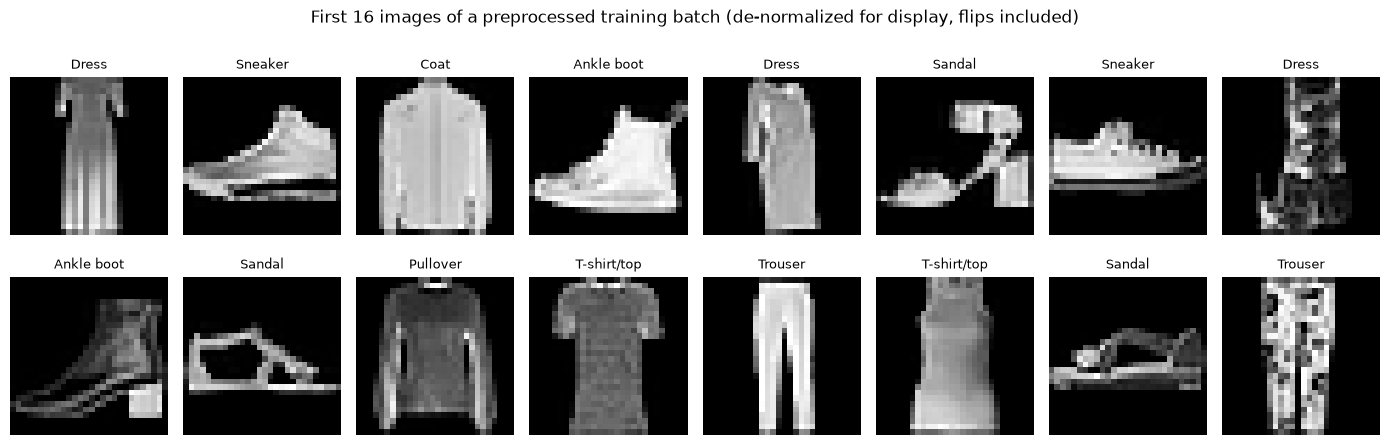

In [7]:
# One example training batch after preprocessing
set_seed(SPLIT_SEED)
xb, yb = next(iter(make_train_loader(SPLIT_SEED)))
print(f"Batch images: shape {tuple(xb.shape)}, dtype {xb.dtype}, mean {xb.mean():.3f}, std {xb.std():.3f}, "
      f"min {xb.min():.3f}, max {xb.max():.3f}")
print(f"Batch labels: shape {tuple(yb.shape)}, dtype {yb.dtype}, first 16 = {yb[:16].tolist()}")

fig, axes = plt.subplots(2, 8, figsize=(14, 4.8))
for i, ax in enumerate(axes.flat):
    ax.imshow((xb[i, 0] * NORM_STD + NORM_MEAN).clamp(0, 1), cmap="gray")
    ax.set_title(CLASS_NAMES[yb[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("First 16 images of a preprocessed training batch (de-normalized for display, flips included)")
plt.tight_layout()
save_fig("example_batch")
plt.show()

## Section 5: Models
All models receive the image **flattened to a 784-dimensional vector**, so neither model knows which pixels are neighbours. This is the key inductive-bias limitation that the CNN, LSTM/GRU and Transformer in `02_architecture_comparison.ipynb` are meant to address.

**Linear / softmax classifier** - a single affine map $z = Wx + b$ with $W \in \mathbb{R}^{10 \times 784}$, $b \in \mathbb{R}^{10}$ (7,850 parameters). Each row of $W$ is a "template" image for one class, and the class score is the dot product between the input and that template. Decision boundaries are hyperplanes in pixel space, and the training problem is convex. The model outputs raw logits: `nn.CrossEntropyLoss` applies log-softmax internally, so **no softmax is applied before the loss** (doing so would squash gradients and is numerically unstable).

**MLP** - hidden blocks of `Linear -> BatchNorm1d -> ReLU -> Dropout(0.2)`, followed by a linear output layer:
- **ReLU** $\max(0, u)$ adds the non-linearity that lets the network combine pixel features into non-linear decision boundaries. It does not saturate for positive inputs, so gradients do not vanish as with sigmoid / tanh.
- **BatchNorm1d** normalizes each hidden unit over the batch, which keeps activations well scaled and allows a larger learning rate. It uses batch statistics in training and running averages in evaluation, so `model.train()` / `model.eval()` must be switched correctly.
- **Dropout(0.2)** randomly zeroes 20% of hidden activations during training, discouraging units from co-adapting and reducing overfitting. It is disabled in evaluation.
- **Weight decay** ($10^{-4}$, decoupled in AdamW) adds an L2-style shrinkage on all weights.

**Capacity ablation:** three MLP sizes (one hidden layer of 128 or 256 units, and two hidden layers of 512-256 units) test whether more capacity and depth help on flattened pixels.

In [8]:
class LinearClassifier(nn.Module):
    def __init__(self, input_dim=28 * 28, num_classes=NUM_CLASSES):
        super().__init__()
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        return self.linear(x.flatten(1))  # raw logits, no softmax


class MLP(nn.Module):
    def __init__(self, layer_dims, dropout_rate=0.2):
        super().__init__()
        layers = []
        for in_dim, out_dim in zip(layer_dims[:-2], layer_dims[1:-1]):
            layers += [nn.Linear(in_dim, out_dim), nn.BatchNorm1d(out_dim), nn.ReLU(), nn.Dropout(dropout_rate)]
        layers.append(nn.Linear(layer_dims[-2], layer_dims[-1]))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x.flatten(1))  # raw logits, no softmax


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# key -> (display name, factory). Factories let every run build a fresh model right after seeding.
MODEL_SPECS = {
    "linear": ("Linear (784-10)", lambda: LinearClassifier()),
    "mlp_a": ("MLP-A (784-128-10)", lambda: MLP([784, 128, 10])),
    "mlp_b": ("MLP-B (784-256-10)", lambda: MLP([784, 256, 10])),
    "mlp_c": ("MLP-C (784-512-256-10)", lambda: MLP([784, 512, 256, 10])),
}
DISPLAY = {k: v[0] for k, v in MODEL_SPECS.items()}

param_counts = {key: count_parameters(factory()) for key, (_, factory) in MODEL_SPECS.items()}
# Sanity check against the closed-form counts (Linear weights + biases, BatchNorm gamma + beta)
assert param_counts["linear"] == 784 * 10 + 10
assert param_counts["mlp_a"] == (784 * 128 + 128) + 2 * 128 + (128 * 10 + 10)
print(pd.DataFrame({"Model": [DISPLAY[k] for k in param_counts], "Trainable parameters": list(param_counts.values())}).to_string(index=False))
print()
print(MODEL_SPECS["mlp_c"][1]())

                 Model  Trainable parameters
       Linear (784-10)                  7850
    MLP-A (784-128-10)                102026
    MLP-B (784-256-10)                204042
MLP-C (784-512-256-10)                537354

MLP(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=256, out_features=10, bias=True)
  )
)


## Section 6: Training, Evaluation and Timing Engine
- **Loss accumulation:** batch losses are weighted by batch size, so the epoch loss is the exact per-sample mean even when the last batch is smaller. Losses are summed on the GPU and synchronized once per epoch.
- **Train metrics** are collected in `model.train()` mode, i.e. with dropout active and on flipped images. They are therefore a slightly pessimistic estimate and not directly comparable with validation metrics.
- **Training time** = wall-clock time of the training passes only (data loading + forward + backward + update), excluding validation. The GPU is synchronized before reading the clock, and a warm-up step runs before the first experiment so CUDA / cuBLAS initialization is not charged to the first model.
- **Inference time** is measured on a batch already resident on the device, so it reflects model compute only and not data loading. We report latency at batch size 1 (ms per image, the online setting) and per-sample time at batch size 512 (the throughput setting).

In [9]:
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


def train_epoch(model, loader, criterion, optimizer):
    model.train()
    loss_sum = torch.zeros((), device=device)
    preds, targets = [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.detach() * x.size(0)
        preds.append(logits.argmax(1))
        targets.append(y)
    preds = torch.cat(preds).cpu().numpy()
    targets = torch.cat(targets).cpu().numpy()
    return {
        "loss": loss_sum.item() / len(targets),
        "acc": float((preds == targets).mean()),
        "f1": f1_score(targets, preds, average="macro"),
    }


@torch.no_grad()
def evaluate(model, loader, criterion, return_outputs=False):
    model.eval()
    loss_sum = torch.zeros((), device=device)
    logits_all, targets = [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        logits = model(x)
        loss_sum += criterion(logits, y) * x.size(0)
        logits_all.append(logits)
        targets.append(y)
    logits_all = torch.cat(logits_all)
    preds = logits_all.argmax(1).cpu().numpy()
    targets = torch.cat(targets).cpu().numpy()
    out = {
        "loss": loss_sum.item() / len(targets),
        "acc": float((preds == targets).mean()),
        "f1": f1_score(targets, preds, average="macro"),
    }
    if return_outputs:
        out.update(preds=preds, targets=targets, probs=F.softmax(logits_all, dim=1).cpu().numpy())
    return out


@torch.inference_mode()
def measure_inference_ms(model, batch_size, n_iters, warmup=20):
    """Average milliseconds per image for a forward pass on a device-resident batch."""
    model.eval()
    x = torch.randn(batch_size, 1, 28, 28, device=device)
    for _ in range(warmup):
        model(x)
    sync()
    start = time.perf_counter()
    for _ in range(n_iters):
        model(x)
    sync()
    return (time.perf_counter() - start) / (n_iters * batch_size) * 1000.0


def warm_up_device():
    set_seed(0)
    m = MLP([784, 256, 10]).to(device)
    opt = torch.optim.AdamW(m.parameters())
    for _ in range(20):
        opt.zero_grad()
        F.cross_entropy(m(torch.randn(BATCH_SIZE, 1, 28, 28, device=device)), torch.randint(0, 10, (BATCH_SIZE,), device=device)).backward()
        opt.step()
    sync()

## Section 7: Experimental Setup
| Item | Setting |
|---|---|
| Optimizer | AdamW, lr $10^{-3}$, weight decay $10^{-4}$ |
| Scheduler | CosineAnnealingLR from $10^{-3}$ to $10^{-5}$ over 20 epochs (stepped per epoch) |
| Epochs / batch size | 20 / 64 |
| Loss | `nn.CrossEntropyLoss` on raw logits |
| Regularization | weight decay (all), BatchNorm + Dropout 0.2 (MLPs), horizontal flip (all) |
| Checkpoint rule | epoch with the highest **validation macro-F1** (ties keep the earlier epoch) |
| Test protocol | test set evaluated once per run, after checkpoint selection; never used to choose anything |
| Seeds | split seed 42 (shared); training seeds 42, 123, 2026 |
| Hyperparameter selection | common defaults shared by all models, not tuned per model, so that differences come from the architecture |

**Experiment E1 - Linear vs. MLP (representation power)**
- *Hypothesis:* a non-linear MLP beats the linear classifier on flattened pixels, because several classes are not linearly separable in pixel space.
- *Changed factor:* model family. *Fixed:* data split, preprocessing, optimizer, schedule, epochs, seeds.
- *Metrics:* test accuracy and macro-F1 (mean ± std over 3 seeds), parameters, training time, inference time.
- *Decision criterion:* the hypothesis is supported if the macro-F1 gap is larger than the sum of both models' standard deviations.

**Experiment E2 - MLP capacity ablation (width and depth)**
- *Hypothesis:* larger / deeper MLPs improve macro-F1, with diminishing returns, while increasing the train-validation gap.
- *Changed factor:* hidden layer sizes (128; 256; 512-256). *Fixed:* everything else.
- *Decision criterion:* same as E1, plus the train-validation accuracy gap at the selected epoch.

In [10]:
EPOCHS = 20
INITIAL_LR = 1e-3
MIN_LR = 1e-5
WEIGHT_DECAY = 1e-4
criterion = nn.CrossEntropyLoss()

CONFIG = {
    "epochs": EPOCHS, "lr": INITIAL_LR, "min_lr": MIN_LR, "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE, "eval_batch_size": EVAL_BATCH_SIZE, "hflip_p": HFLIP_P,
    "optimizer": "AdamW", "scheduler": "CosineAnnealingLR", "selection_metric": "val_macro_f1",
    "norm_mean": NORM_MEAN, "norm_std": NORM_STD, "models": DISPLAY, **ENV_INFO,
}
with open("./results/config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)


def checkpoint_path(key, seed):
    return f"./checkpoints/{key}_seed{seed}_best.pt"


def fit(key, seed):
    set_seed(seed)
    model = MODEL_SPECS[key][1]().to(device)
    train_loader = make_train_loader(seed)
    optimizer = torch.optim.AdamW(model.parameters(), lr=INITIAL_LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=MIN_LR)

    hist = {k: [] for k in ["lr", "train_loss", "train_acc", "train_f1", "val_loss", "val_acc", "val_f1", "epoch_time"]}
    best = {"val_f1": -1.0}
    for epoch in range(1, EPOCHS + 1):
        hist["lr"].append(optimizer.param_groups[0]["lr"])  # LR actually used in this epoch
        sync()
        t0 = time.perf_counter()
        tr = train_epoch(model, train_loader, criterion, optimizer)
        sync()
        hist["epoch_time"].append(time.perf_counter() - t0)
        va = evaluate(model, val_loader, criterion)
        scheduler.step()

        for split, m in [("train", tr), ("val", va)]:
            for metric in ["loss", "acc", "f1"]:
                hist[f"{split}_{metric}"].append(m[metric])

        if va["f1"] > best["val_f1"]:
            best = {"epoch": epoch, "val_f1": va["f1"], "val_acc": va["acc"], "val_loss": va["loss"], "train_acc": tr["acc"]}
            torch.save(model.state_dict(), checkpoint_path(key, seed))

        if epoch % 5 == 0 or epoch == 1:
            print(f"  [{DISPLAY[key]} | seed {seed}] epoch {epoch:02d}/{EPOCHS} lr {hist['lr'][-1]:.6f} | "
                  f"train loss {tr['loss']:.4f} acc {tr['acc']*100:.2f}% | "
                  f"val loss {va['loss']:.4f} acc {va['acc']*100:.2f}% F1 {va['f1']:.4f}")

    model.load_state_dict(torch.load(checkpoint_path(key, seed), map_location=device, weights_only=True))
    return model, hist, best


warm_up_device()
runs, histories = [], {}
for key in MODEL_SPECS:
    print("=" * 100)
    print(f"{DISPLAY[key]}  ({param_counts[key]:,} parameters)")
    print("=" * 100)
    for seed in TRAIN_SEEDS:
        model, hist, best = fit(key, seed)
        test = evaluate(model, test_loader, criterion)
        runs.append({
            "key": key, "Model": DISPLAY[key], "seed": seed, "Parameters": param_counts[key],
            "Best epoch": best["epoch"],
            "Train acc @best (%)": best["train_acc"] * 100,
            "Val acc @best (%)": best["val_acc"] * 100,
            "Val macro-F1": best["val_f1"],
            "Test acc (%)": test["acc"] * 100,
            "Test macro-F1": test["f1"],
            "Train time (s)": sum(hist["epoch_time"]),
            "Latency bs=1 (ms/img)": measure_inference_ms(model, batch_size=1, n_iters=500),
            "Time bs=512 (ms/img)": measure_inference_ms(model, batch_size=512, n_iters=50),
            "Checkpoint": checkpoint_path(key, seed),
        })
        histories[(key, seed)] = hist
        r = runs[-1]
        print(f"  -> seed {seed}: best epoch {r['Best epoch']}, val F1 {r['Val macro-F1']:.4f}, "
              f"test acc {r['Test acc (%)']:.2f}%, test F1 {r['Test macro-F1']:.4f}, train time {r['Train time (s)']:.1f}s\n")

df_runs = pd.DataFrame(runs)
df_runs.to_csv("./results/runs.csv", index=False)
with open("./results/histories.json", "w") as f:
    json.dump({f"{k}_seed{s}": h for (k, s), h in histories.items()}, f)
print("Saved results/runs.csv, results/histories.json, results/config.json and checkpoints/*.pt")

Linear (784-10)  (7,850 parameters)


  [Linear (784-10) | seed 42] epoch 01/20 lr 0.001000 | train loss 0.6247 acc 78.65% | val loss 0.5639 acc 80.78% F1 0.8086


  [Linear (784-10) | seed 42] epoch 05/20 lr 0.000905 | train loss 0.4960 acc 82.99% | val loss 0.5412 acc 82.02% F1 0.8193


  [Linear (784-10) | seed 42] epoch 10/20 lr 0.000582 | train loss 0.4744 acc 83.86% | val loss 0.5008 acc 83.07% F1 0.8307


  [Linear (784-10) | seed 42] epoch 15/20 lr 0.000214 | train loss 0.4576 acc 84.51% | val loss 0.5031 acc 83.06% F1 0.8303


...

  [MLP-C (784-512-256-10) | seed 2026] epoch 05/20 lr 0.000905 | train loss 0.3244 acc 87.92% | val loss 0.3309 acc 88.23% F1 0.8819


  [MLP-C (784-512-256-10) | seed 2026] epoch 10/20 lr 0.000582 | train loss 0.2556 acc 90.47% | val loss 0.2995 acc 89.44% F1 0.8938


  [MLP-C (784-512-256-10) | seed 2026] epoch 15/20 lr 0.000214 | train loss 0.1997 acc 92.47% | val loss 0.2797 acc 89.99% F1 0.8999


  [MLP-C (784-512-256-10) | seed 2026] epoch 20/20 lr 0.000016 | train loss 0.1737 acc 93.42% | val loss 0.2719 acc 90.32% F1 0.9031


  -> seed 2026: best epoch 19, val F1 0.9042, test acc 89.94%, test F1 0.8990, train time 56.0s

Saved results/runs.csv, results/histories.json, results/config.json and checkpoints/*.pt


## Section 8: Quantitative Results
All numbers are mean ± std over the training seeds. Validation numbers are at the selected checkpoint (same epoch for accuracy and F1).

In [11]:
METRIC_COLS = ["Val macro-F1", "Test acc (%)", "Test macro-F1", "Train acc @best (%)", "Val acc @best (%)",
               "Best epoch", "Train time (s)", "Latency bs=1 (ms/img)", "Time bs=512 (ms/img)"]
agg = df_runs.groupby("key", sort=False)[METRIC_COLS].agg(["mean", "std"])
agg[("Gap train-val (pp)", "mean")] = (df_runs.assign(gap=df_runs["Train acc @best (%)"] - df_runs["Val acc @best (%)"])
                                        .groupby("key", sort=False)["gap"].mean())


def fmt(col, digits, scale=1.0):
    mean, std = agg[(col, "mean")] * scale, agg[(col, "std")].fillna(0) * scale
    return mean.map(f"{{:.{digits}f}}".format) + " ± " + std.map(f"{{:.{digits}f}}".format)


summary = pd.DataFrame({
    "Model": [DISPLAY[k] for k in agg.index],
    "Params": [f"{param_counts[k]:,}" for k in agg.index],
    "Test acc (%)": fmt("Test acc (%)", 2).values,
    "Test macro-F1": fmt("Test macro-F1", 4).values,
    "Val macro-F1": fmt("Val macro-F1", 4).values,
    "Best epoch": fmt("Best epoch", 1).values,
    "Train-val gap (pp)": agg[("Gap train-val (pp)", "mean")].round(2).values,
    "Train time (s)": fmt("Train time (s)", 1).values,
    "Latency bs=1 (µs/img)": fmt("Latency bs=1 (ms/img)", 1, scale=1000).values,
    "bs=512 (µs/img)": fmt("Time bs=512 (ms/img)", 2, scale=1000).values,
})
summary.to_csv("./results/summary.csv", index=False)
display(summary)

# E1 / E2 decision criterion: mean gap vs. the sum of standard deviations
print("Pairwise test macro-F1 comparisons (criterion: |diff| > std_A + std_B):")
pairwise = []
for a, b in [("linear", "mlp_a"), ("mlp_a", "mlp_b"), ("mlp_b", "mlp_c"), ("linear", "mlp_c")]:
    diff = agg.loc[b, ("Test macro-F1", "mean")] - agg.loc[a, ("Test macro-F1", "mean")]
    noise = np.nan_to_num(agg.loc[a, ("Test macro-F1", "std")] + agg.loc[b, ("Test macro-F1", "std")])
    verdict = "clear difference" if abs(diff) > noise else "within seed noise"
    pairwise.append((a, b, diff, noise, verdict))
    print(f"  {DISPLAY[b]:<24} vs {DISPLAY[a]:<24}: {diff:+.4f}  (std sum {noise:.4f}) -> {verdict}")

,Model,Params,Test acc (%),Test macro-F1,Val macro-F1,Best epoch,Train-val gap (pp),Train time (s),Latency bs=1 (µs/img),bs=512 (µs/img)
0,Linear (784-10),"7,850",82.60 ± 0.15,0.8244 ± 0.0016,0.8331 ± 0.0006,18.7 ± 0.6,1.24,21.2 ± 0.5,6.9 ± 2.0,0.13 ± 0.00
1,MLP-A (784-128-10),"102,026",88.71 ± 0.06,0.8869 ± 0.0006,0.8910 ± 0.0004,18.0 ± 1.7,1.56,28.8 ± 1.4,23.1 ± 4.7,0.66 ± 0.01
2,MLP-B (784-256-10),"204,042",89.34 ± 0.10,0.8932 ± 0.0010,0.8966 ± 0.0013,19.3 ± 0.6,2.52,34.1 ± 1.3,21.6 ± 1.1,1.15 ± 0.16
3,MLP-C (784-512-256-10),"537,354",89.85 ± 0.09,0.8983 ± 0.0007,0.9042 ± 0.0006,18.7 ± 1.5,2.86,57.2 ± 3.2,69.2 ± 36.1,3.67 ± 0.12


Pairwise test macro-F1 comparisons (criterion: |diff| > std_A + std_B):
  MLP-A (784-128-10)       vs Linear (784-10)         : +0.0625  (std sum 0.0022) -> clear difference
  MLP-B (784-256-10)       vs MLP-A (784-128-10)      : +0.0063  (std sum 0.0015) -> clear difference
  MLP-C (784-512-256-10)   vs MLP-B (784-256-10)      : +0.0050  (std sum 0.0017) -> clear difference
  MLP-C (784-512-256-10)   vs Linear (784-10)         : +0.0739  (std sum 0.0023) -> clear difference


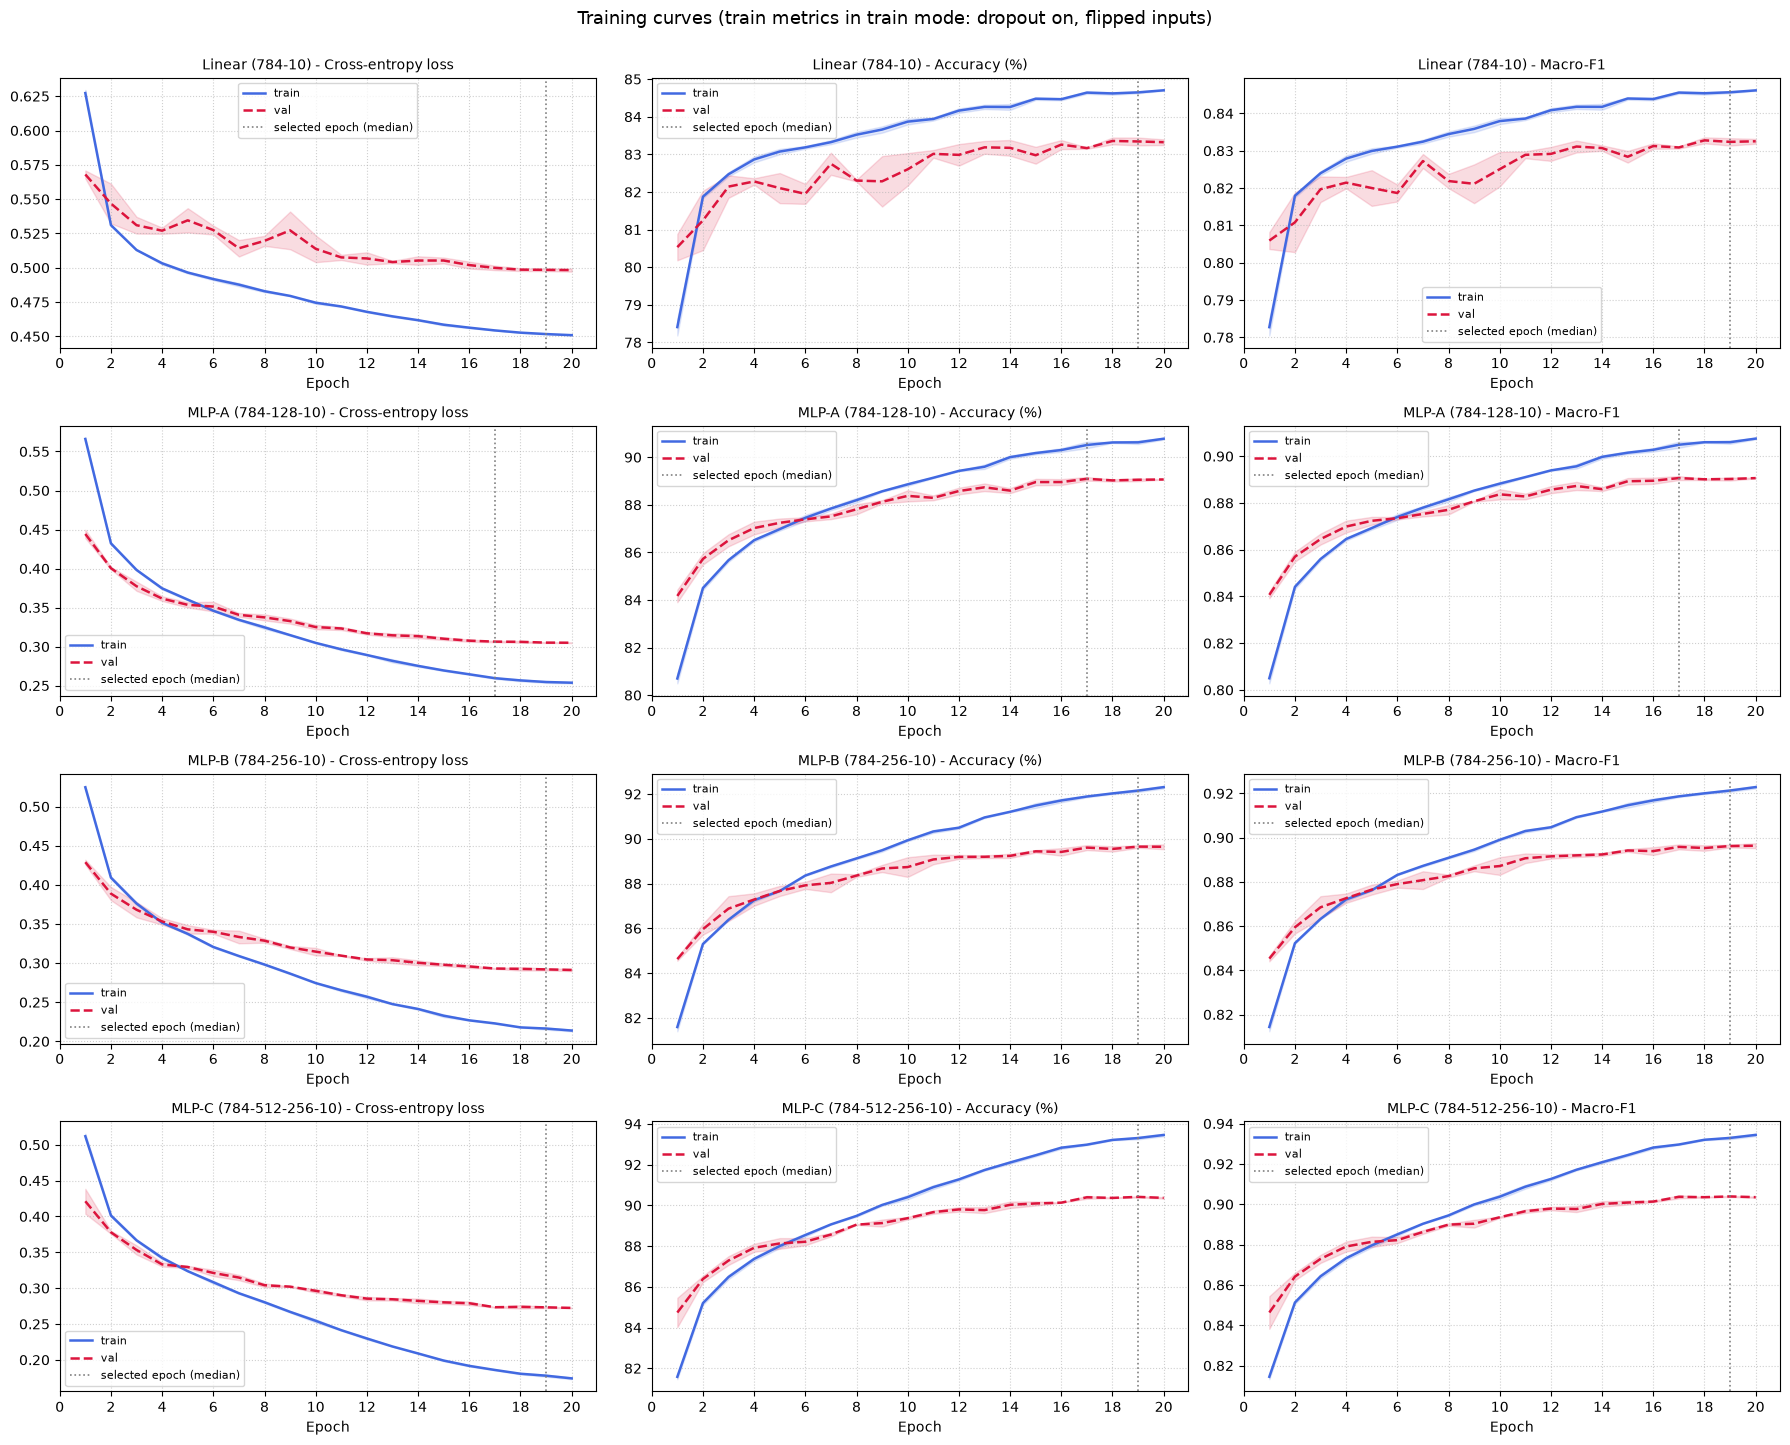

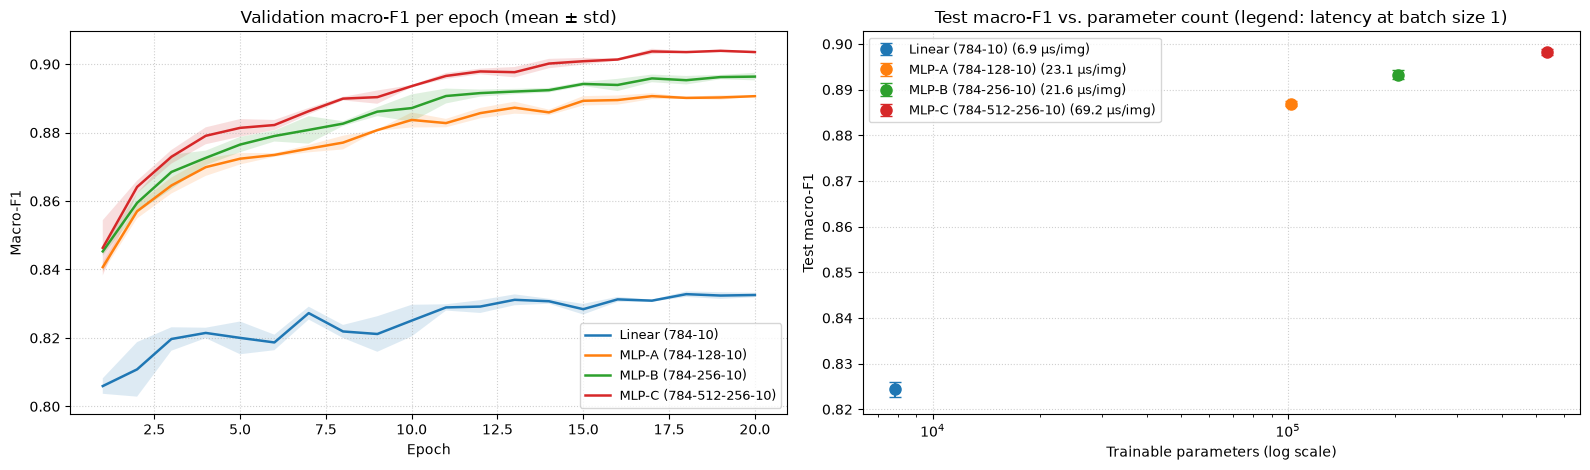

In [12]:
# Learning curves: mean over seeds (line) with ± 1 std band
fig, axes = plt.subplots(len(MODEL_SPECS), 3, figsize=(18, 3.6 * len(MODEL_SPECS)))
epochs_axis = np.arange(1, EPOCHS + 1)
panels = [("loss", "Cross-entropy loss", 1), ("acc", "Accuracy (%)", 100), ("f1", "Macro-F1", 1)]

for row, key in enumerate(MODEL_SPECS):
    for col, (metric, ylabel, scale) in enumerate(panels):
        ax = axes[row, col]
        for split, color, style in [("train", "royalblue", "-"), ("val", "crimson", "--")]:
            curves = np.array([histories[(key, s)][f"{split}_{metric}"] for s in TRAIN_SEEDS]) * scale
            mean, std = curves.mean(0), curves.std(0)
            ax.plot(epochs_axis, mean, color=color, linestyle=style, lw=1.8, label=f"{split}")
            ax.fill_between(epochs_axis, mean - std, mean + std, color=color, alpha=0.15)
        best_epochs = df_runs.loc[df_runs.key == key, "Best epoch"]
        ax.axvline(best_epochs.median(), color="gray", linestyle=":", lw=1.2, label="selected epoch (median)")
        ax.set_title(f"{DISPLAY[key]} - {ylabel}", fontsize=10)
        ax.set_xlabel("Epoch")
        ax.set_xticks(range(0, EPOCHS + 1, 2))
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.legend(fontsize=8)
plt.suptitle("Training curves (train metrics in train mode: dropout on, flipped inputs)", fontsize=13, y=1.0)
plt.tight_layout()
save_fig("learning_curves")
plt.show()

# Model comparison: validation macro-F1 per epoch and the accuracy / size / speed trade-off
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for key in MODEL_SPECS:
    curves = np.array([histories[(key, s)]["val_f1"] for s in TRAIN_SEEDS])
    axes[0].plot(epochs_axis, curves.mean(0), lw=1.8, label=DISPLAY[key])
    axes[0].fill_between(epochs_axis, curves.mean(0) - curves.std(0), curves.mean(0) + curves.std(0), alpha=0.15)
axes[0].set_title("Validation macro-F1 per epoch (mean ± std)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Macro-F1")
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(fontsize=9)

for key in MODEL_SPECS:
    axes[1].errorbar(param_counts[key], agg.loc[key, ("Test macro-F1", "mean")], yerr=agg.loc[key, ("Test macro-F1", "std")],
                     fmt="o", capsize=4, markersize=8, label=f"{DISPLAY[key]} ({agg.loc[key, ('Latency bs=1 (ms/img)', 'mean')] * 1000:.1f} µs/img)")
axes[1].set_xscale("log")
axes[1].set_title("Test macro-F1 vs. parameter count (legend: latency at batch size 1)")
axes[1].set_xlabel("Trainable parameters (log scale)")
axes[1].set_ylabel("Test macro-F1")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(fontsize=9)
plt.tight_layout()
save_fig("model_comparison")
plt.show()

## Section 9: Error Analysis
- The model for the deep dive is chosen by **mean validation macro-F1**, not by test results.
- Qualitative analysis uses the checkpoint of the first training seed of each model.
- The linear classifier is analysed alongside the best MLP, so we can see which errors extra capacity fixes and which remain.

Selected by mean validation macro-F1: MLP-C (784-512-256-10) (analysis uses seed 42)



Per-class report on the test set (MLP-C (784-512-256-10), seed 42):
              precision    recall  f1-score   support

 T-shirt/top     0.8428    0.8420    0.8424      1000
     Trouser     0.9929    0.9800    0.9864      1000
    Pullover     0.8107    0.8610    0.8351      1000
       Dress     0.8924    0.9210    0.9065      1000
        Coat     0.8511    0.8230    0.8368      1000
      Sandal     0.9676    0.9560    0.9618      1000
       Shirt     0.7497    0.7130    0.7309      1000
     Sneaker     0.9277    0.9620    0.9445      1000
         Bag     0.9819    0.9760    0.9789      1000
  Ankle boot     0.9654    0.9490    0.9571      1000

    accuracy                         0.8983     10000
   macro avg     0.8982    0.8983    0.8981     10000
weighted avg     0.8982    0.8983    0.8981     10000

Per-class test F1 by model:


,Linear (784-10),MLP-A (784-128-10),MLP-B (784-256-10),MLP-C (784-512-256-10),Gain best vs linear
Shirt,0.5713,0.7038,0.7194,0.7309,0.1596
Pullover,0.7301,0.8050,0.8160,0.8351,0.1050
Coat,0.7448,0.8166,0.8284,0.8368,0.0920
T-shirt/top,0.8072,0.8429,0.8492,0.8424,0.0352
Dress,0.8513,0.9008,0.8953,0.9065,0.0552
Sneaker,0.8960,0.9408,0.9422,0.9445,0.0485
Ankle boot,0.8949,0.9533,0.9531,0.9571,0.0622
Sandal,0.8777,0.9599,0.9592,0.9618,0.0841
Bag,0.9086,0.9719,0.9740,0.9789,0.0703
Trouser,0.9642,0.9808,0.9844,0.9864,0.0222


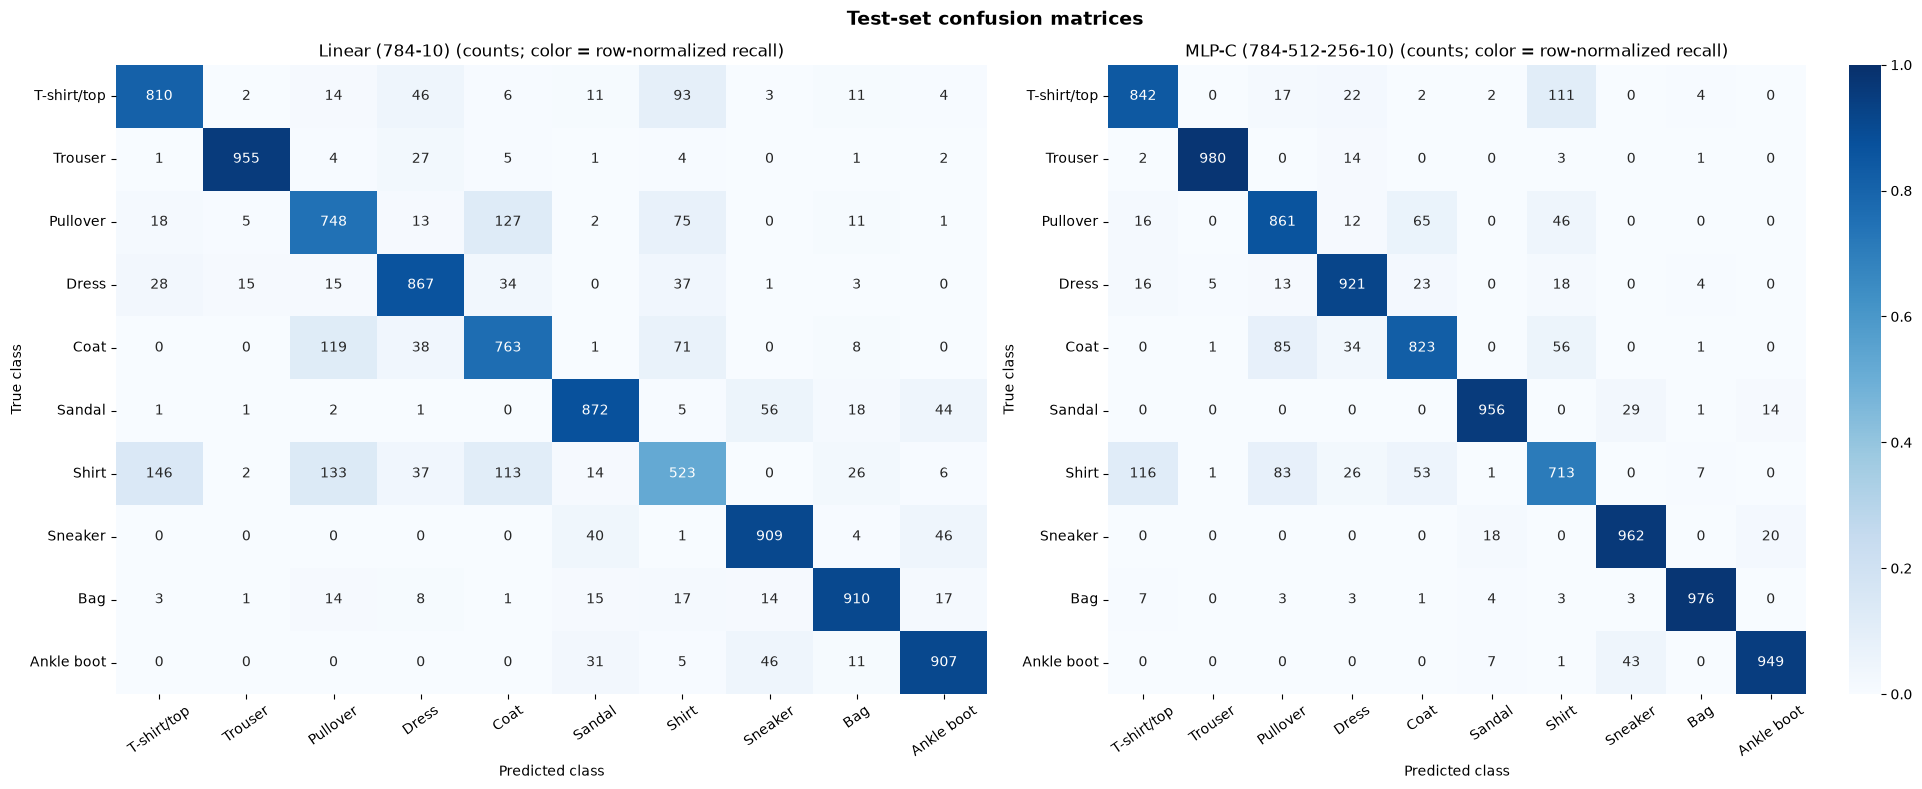

In [13]:
best_key = agg[("Val macro-F1", "mean")].idxmax()
ref_seed = TRAIN_SEEDS[0]
print(f"Selected by mean validation macro-F1: {DISPLAY[best_key]} (analysis uses seed {ref_seed})\n")


def load_model(key, seed):
    model = MODEL_SPECS[key][1]().to(device)
    model.load_state_dict(torch.load(checkpoint_path(key, seed), map_location=device, weights_only=True))
    model.eval()
    return model


outputs = {key: evaluate(load_model(key, ref_seed), test_loader, criterion, return_outputs=True) for key in MODEL_SPECS}
best_out = outputs[best_key]

print(f"Per-class report on the test set ({DISPLAY[best_key]}, seed {ref_seed}):")
print(classification_report(best_out["targets"], best_out["preds"], target_names=CLASS_NAMES, digits=4))

per_class_f1 = pd.DataFrame(
    {DISPLAY[k]: f1_score(o["targets"], o["preds"], average=None) for k, o in outputs.items()},
    index=CLASS_NAMES,
).round(4)
per_class_f1["Gain best vs linear"] = (per_class_f1[DISPLAY[best_key]] - per_class_f1[DISPLAY["linear"]]).round(4)
print("Per-class test F1 by model:")
display(per_class_f1.sort_values(DISPLAY[best_key]))

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, key in zip(axes, ["linear", best_key]):
    cm = confusion_matrix(outputs[key]["targets"], outputs[key]["preds"])
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar=key == best_key,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{DISPLAY[key]} (counts; color = row-normalized recall)", fontsize=12)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", rotation=35)
plt.suptitle("Test-set confusion matrices", fontsize=14, fontweight="bold")
plt.tight_layout()
save_fig("confusion_matrices")
plt.show()

Total test errors: 1017 / 10000 (10.17%)



,Errors,Share of all errors (%)
Upper-body garment confusion (T-shirt/Pullover/Coat/Shirt),650,63.9
Dress vs. other garment,190,18.7
Footwear confusion (Sandal/Sneaker/Ankle boot),131,12.9
Other,46,4.5


Most frequent confusion pairs:


,True,Predicted,Count,% of true class,% of all errors
0,Shirt,T-shirt/top,116,11.6,11.4
1,T-shirt/top,Shirt,111,11.1,10.9
2,Coat,Pullover,85,8.5,8.4
3,Shirt,Pullover,83,8.3,8.2
4,Pullover,Coat,65,6.5,6.4
5,Coat,Shirt,56,5.6,5.5
6,Shirt,Coat,53,5.3,5.2
7,Pullover,Shirt,46,4.6,4.5


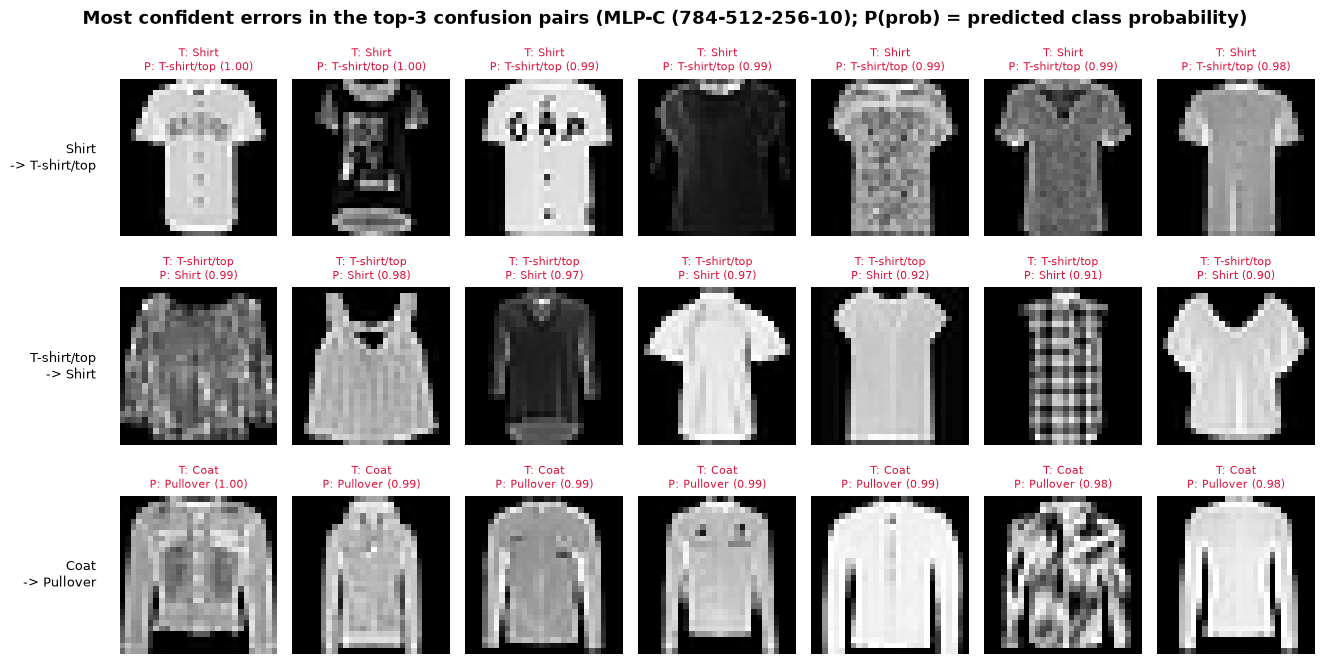

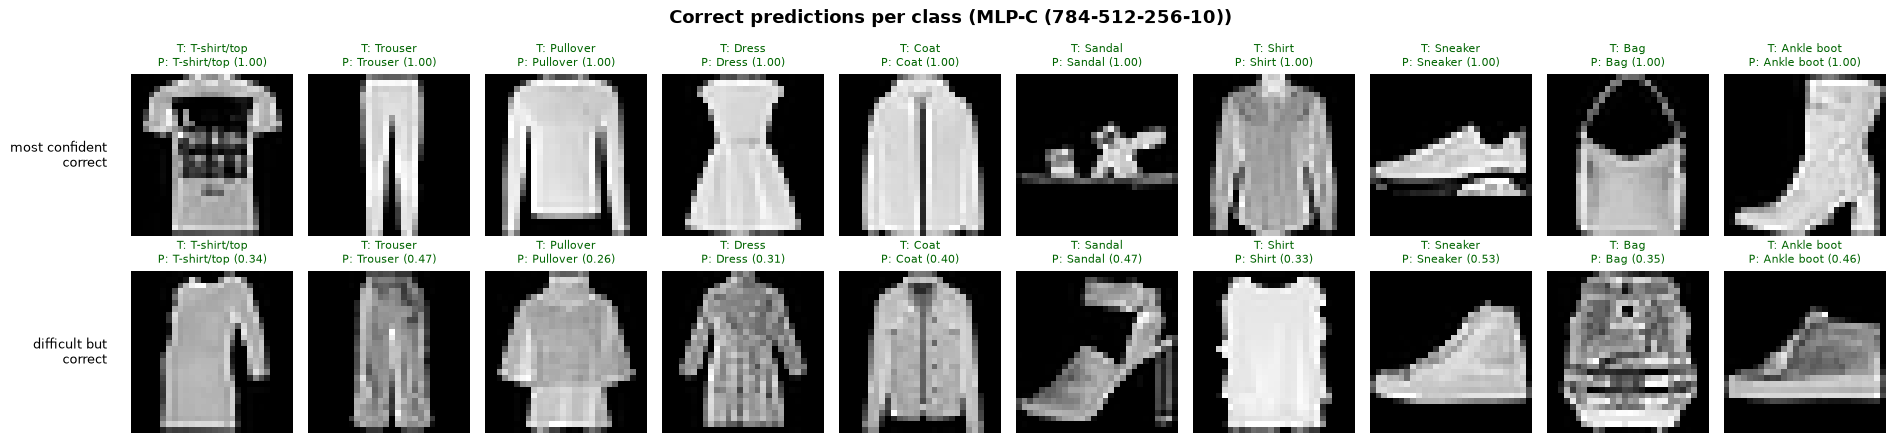

Linear errors fixed by MLP-C (784-512-256-10): 954 | new errors introduced: 235 | errors shared by both: 782


In [14]:
# Error groups and most frequent confusion pairs for the best model
y_true, y_pred, probs = best_out["targets"], best_out["preds"], best_out["probs"]
errors = np.where(y_true != y_pred)[0]
print(f"Total test errors: {len(errors)} / {len(y_true)} ({len(errors) / len(y_true) * 100:.2f}%)\n")

UPPER_BODY = {0, 2, 4, 6}   # T-shirt/top, Pullover, Coat, Shirt
FOOTWEAR = {5, 7, 9}        # Sandal, Sneaker, Ankle boot


def error_group(t, p):
    if t in UPPER_BODY and p in UPPER_BODY:
        return "Upper-body garment confusion (T-shirt/Pullover/Coat/Shirt)"
    if t in FOOTWEAR and p in FOOTWEAR:
        return "Footwear confusion (Sandal/Sneaker/Ankle boot)"
    if 3 in (t, p):
        return "Dress vs. other garment"
    return "Other"


groups = pd.Series([error_group(y_true[i], y_pred[i]) for i in errors]).value_counts()
display(pd.DataFrame({"Errors": groups, "Share of all errors (%)": (groups / len(errors) * 100).round(1)}))

cm = confusion_matrix(y_true, y_pred)
pairs = [(t, p, cm[t, p]) for t in range(NUM_CLASSES) for p in range(NUM_CLASSES) if t != p and cm[t, p] > 0]
pairs.sort(key=lambda r: -r[2])
top_pairs = pd.DataFrame([{
    "True": CLASS_NAMES[t], "Predicted": CLASS_NAMES[p], "Count": n,
    "% of true class": round(n / cm[t].sum() * 100, 1), "% of all errors": round(n / len(errors) * 100, 1),
} for t, p, n in pairs[:8]])
print("Most frequent confusion pairs:")
display(top_pairs)


def show_grid(rows, title, fig_name):
    """rows: list of (row_label, [test indices]) drawn from the raw test images."""
    n_cols = max(len(idx) for _, idx in rows)
    fig, axes = plt.subplots(len(rows), n_cols, figsize=(1.9 * n_cols, 2.3 * len(rows)), squeeze=False)
    for r, (label, idxs) in enumerate(rows):
        for c in range(n_cols):
            ax = axes[r, c]
            ax.axis("off")
            if c >= len(idxs):
                continue
            i = idxs[c]
            ok = y_true[i] == y_pred[i]
            ax.imshow(test_images[i], cmap="gray")
            ax.set_title(f"T: {CLASS_NAMES[y_true[i]]}\nP: {CLASS_NAMES[y_pred[i]]} ({probs[i, y_pred[i]]:.2f})",
                         fontsize=8, color="darkgreen" if ok else "crimson")
        axes[r, 0].text(-0.15, 0.5, label, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
    plt.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    save_fig(fig_name)
    plt.show()


# Most confident mistakes for the three most frequent confusion pairs
rows = []
for t, p, _ in pairs[:3]:
    idx = np.where((y_true == t) & (y_pred == p))[0]
    idx = idx[np.argsort(-probs[idx, p])][:7]
    rows.append((f"{CLASS_NAMES[t]}\n-> {CLASS_NAMES[p]}", idx.tolist()))
show_grid(rows, f"Most confident errors in the top-3 confusion pairs ({DISPLAY[best_key]}; P(prob) = predicted class probability)",
          "errors_top_pairs")

# Correct predictions: most confident correct and hardest correct (lowest confidence) per class
correct = y_true == y_pred
easy, hard = [], []
for c in range(NUM_CLASSES):
    idx = np.where(correct & (y_true == c))[0]
    order = np.argsort(probs[idx, c])
    easy.append(idx[order[-1]])
    hard.append(idx[order[0]])
show_grid([("most confident\ncorrect", easy), ("difficult but\ncorrect", hard)],
          f"Correct predictions per class ({DISPLAY[best_key]})", "correct_examples")

# Which errors does the MLP fix compared with the linear model?
lin_pred = outputs["linear"]["preds"]
fixed = np.sum((lin_pred != y_true) & (y_pred == y_true))
broken = np.sum((lin_pred == y_true) & (y_pred != y_true))
both = np.sum((lin_pred != y_true) & (y_pred != y_true))
print(f"Linear errors fixed by {DISPLAY[best_key]}: {fixed} | new errors introduced: {broken} | errors shared by both: {both}")

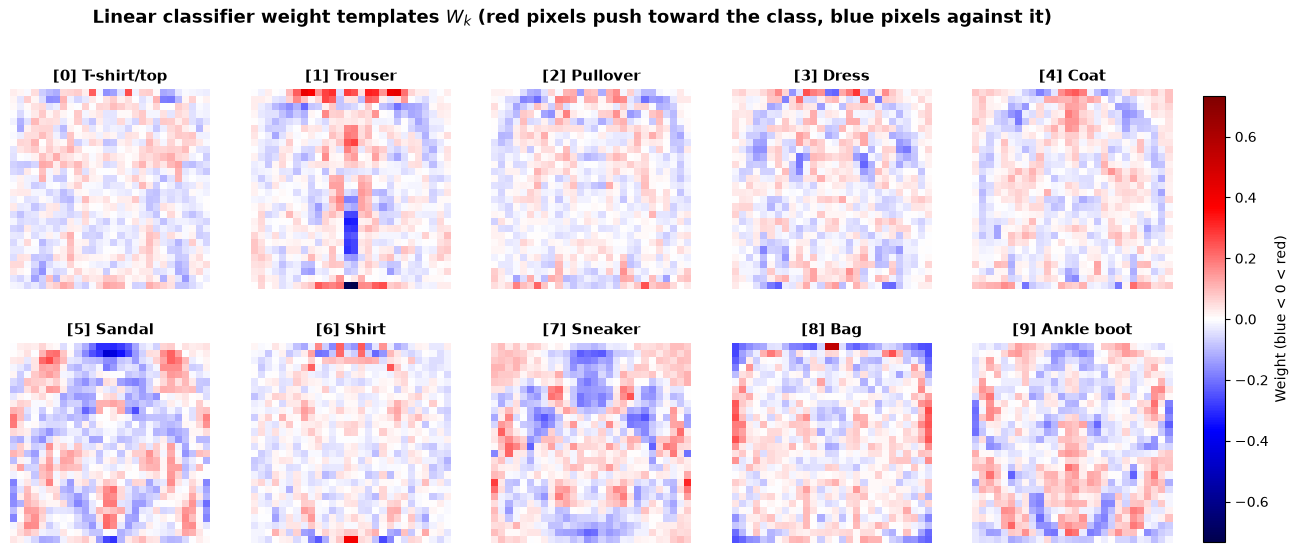

In [15]:
# Linear classifier weight templates: each row of W reshaped to 28 x 28
linear_weights = load_model("linear", ref_seed).linear.weight.detach().cpu().numpy()

fig, axes = plt.subplots(2, 5, figsize=(15, 6.2))
v_abs = np.abs(linear_weights).max()   # one shared symmetric scale so templates are comparable
for i, ax in enumerate(axes.flat):
    im = ax.imshow(linear_weights[i].reshape(28, 28), cmap="seismic", vmin=-v_abs, vmax=v_abs)
    ax.set_title(f"[{i}] {CLASS_NAMES[i]}", fontsize=11, fontweight="bold")
    ax.axis("off")
fig.subplots_adjust(right=0.9, top=0.86)
cbar = fig.colorbar(im, cax=fig.add_axes([0.92, 0.12, 0.015, 0.72]))
cbar.set_label("Weight (blue < 0 < red)")
fig.suptitle("Linear classifier weight templates $W_k$ (red pixels push toward the class, blue pixels against it)",
             fontsize=13, fontweight="bold")
save_fig("linear_templates")
plt.show()

In [16]:
# Auto-generated key findings, so the discussion below is always tied to the numbers of this run
lin, best = agg.loc["linear"], agg.loc[best_key]
worst_cls = per_class_f1[DISPLAY[best_key]].idxmin()
print("KEY FINDINGS (this run)")
print(f"- {DISPLAY[best_key]} vs Linear: test macro-F1 {best[('Test macro-F1', 'mean')]:.4f} vs {lin[('Test macro-F1', 'mean')]:.4f} "
      f"(+{(best[('Test macro-F1', 'mean')] - lin[('Test macro-F1', 'mean')]) * 100:.2f} pp) with "
      f"{param_counts[best_key] / param_counts['linear']:.0f}x more parameters.")
print(f"- Hardest class for {DISPLAY[best_key]}: {worst_cls} (F1 {per_class_f1.loc[worst_cls, DISPLAY[best_key]]:.4f}).")
print(f"- Upper-body garment confusions make up {groups.iloc[0] / len(errors) * 100:.1f}% of its errors "
      f"(largest group: {groups.index[0]}).")
print(f"- Train-val accuracy gap at the selected epoch: Linear {agg.loc['linear', ('Gap train-val (pp)', 'mean')]:.2f} pp, "
      f"{DISPLAY[best_key]} {agg.loc[best_key, ('Gap train-val (pp)', 'mean')]:.2f} pp.")
print(f"- Latency at batch size 1: Linear {lin[('Latency bs=1 (ms/img)', 'mean')]:.4f} ms vs "
      f"{DISPLAY[best_key]} {best[('Latency bs=1 (ms/img)', 'mean')]:.4f} ms per image.")

KEY FINDINGS (this run)
- MLP-C (784-512-256-10) vs Linear: test macro-F1 0.8983 vs 0.8244 (+7.39 pp) with 68x more parameters.
- Hardest class for MLP-C (784-512-256-10): Shirt (F1 0.7309).
- Upper-body garment confusions make up 63.9% of its errors (largest group: Upper-body garment confusion (T-shirt/Pullover/Coat/Shirt)).
- Train-val accuracy gap at the selected epoch: Linear 1.24 pp, MLP-C (784-512-256-10) 2.86 pp.
- Latency at batch size 1: Linear 0.0069 ms vs MLP-C (784-512-256-10) 0.0692 ms per image.


### Export for the LaTeX report
Writes every number used by the report to `results/report_data.tex` (LaTeX macros and table rows) and bundles `results/` and `checkpoints/` into `a1_results.zip`. The report never contains hand-typed numbers: copy the extracted `results/` folder into the report directory and recompile.

In [17]:
import zipfile
from sklearn.metrics import precision_recall_fscore_support


def tex(s):
    s = str(s)
    for a, b in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("_", r"\_"), ("#", r"\#")]:
        s = s.replace(a, b)
    return s


def pm(key, col, digits, scale=1.0):
    mean, std = agg.loc[key, (col, "mean")] * scale, np.nan_to_num(agg.loc[key, (col, "std")]) * scale
    return f"{mean:.{digits}f} $\\pm$ {std:.{digits}f}"


SHORT = {"linear": "Linear", "mlp_a": "MLP-A", "mlp_b": "MLP-B", "mlp_c": "MLP-C"}


def rows(records):
    return "\n".join(" & ".join(tex(v) if not str(v).startswith("$") and "$\\pm$" not in str(v) else str(v) for v in r) + r" \\" for r in records)


upper_name = "Upper-body garment confusion (T-shirt/Pullover/Coat/Shirt)"
prec, rec, f1s, _ = precision_recall_fscore_support(y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0)

macros = {
    "NormMean": f"{NORM_MEAN:.4f}", "NormStd": f"{NORM_STD:.4f}",
    "TrainN": f"{len(train_idx):,}", "ValN": f"{len(val_idx):,}", "TestN": f"{len(test_idx):,}",
    "BackgroundPct": f"{background_pct:.1f}", "StorageMB": f"{storage_mb:.1f}",
    "DupWithinTrain": dup_stats["within Train"], "DupWithinVal": dup_stats["within Validation"],
    "DupWithinTest": dup_stats["within Test"], "DupTrainVal": dup_stats["Validation in Train"],
    "DupTrainTest": dup_stats["Test in Train"], "DupValTest": dup_stats["Test in Validation"],
    "ImbalanceRatio": f"{imbalance.max():.2f}",
    "NumSeeds": len(TRAIN_SEEDS), "SeedList": ", ".join(map(str, TRAIN_SEEDS)), "Epochs": EPOCHS,
    "HardwareName": tex(ENV_INFO["gpu"] or f"CPU ({platform.processor() or platform.machine()})"),
    "BestModel": tex(DISPLAY[best_key]), "RefSeed": ref_seed,
    "BestTestFOne": pm(best_key, "Test macro-F1", 4), "LinTestFOne": pm("linear", "Test macro-F1", 4),
    "BestTestAcc": pm(best_key, "Test acc (%)", 2), "LinTestAcc": pm("linear", "Test acc (%)", 2),
    "FOneGainPP": f"{(agg.loc[best_key, ('Test macro-F1', 'mean')] - agg.loc['linear', ('Test macro-F1', 'mean')]) * 100:.2f}",
    "ParamRatio": f"{param_counts[best_key] / param_counts['linear']:.0f}",
    "WorstClass": tex(worst_cls), "WorstClassFOne": f"{per_class_f1.loc[worst_cls, DISPLAY[best_key]]:.4f}",
    "TotalErrors": len(errors), "ErrorRate": f"{len(errors) / len(y_true) * 100:.2f}",
    "UpperShare": f"{groups.get(upper_name, 0) / len(errors) * 100:.1f}",
    "FixedErrors": fixed, "NewErrors": broken, "SharedErrors": both,
    "LinGap": f"{agg.loc['linear', ('Gap train-val (pp)', 'mean')]:.2f}",
    "BestGap": f"{agg.loc[best_key, ('Gap train-val (pp)', 'mean')]:.2f}",
    "LinLatency": f"{agg.loc['linear', ('Latency bs=1 (ms/img)', 'mean')]:.4f}",
    "BestLatency": f"{agg.loc[best_key, ('Latency bs=1 (ms/img)', 'mean')]:.4f}",
    "ClassDistRows": rows([[c, *dist.loc[c].tolist()] for c in CLASS_NAMES]),
    "EdaStatsRows": rows([[c, f"{eda_class_stats.loc[c, 'mean intensity']:.3f}", f"{eda_class_stats.loc[c, 'foreground ratio']:.3f}"] for c in CLASS_NAMES]),
    "ParamRows": rows([[DISPLAY[k], f"{param_counts[k]:,}"] for k in MODEL_SPECS]),
    "SummaryRows": rows([[DISPLAY[k], f"{param_counts[k]:,}", pm(k, "Test acc (%)", 2), pm(k, "Test macro-F1", 4),
                          pm(k, "Val macro-F1", 4), pm(k, "Best epoch", 1), f"{agg.loc[k, ('Gap train-val (pp)', 'mean')]:.2f}"]
                         for k in MODEL_SPECS]),
    "CostRows": rows([[DISPLAY[k], f"{param_counts[k]:,}", pm(k, "Train time (s)", 1),
                       pm(k, "Latency bs=1 (ms/img)", 1, scale=1000), pm(k, "Time bs=512 (ms/img)", 2, scale=1000)] for k in MODEL_SPECS]),
    "PairwiseRows": rows([[f"{SHORT[b]} vs. {SHORT[a]}", f"{d * 100:+.2f}", f"{n * 100:.2f}", v] for a, b, d, n, v in pairwise]),
    "PerClassRows": rows([[c, *[f"{per_class_f1.loc[c, DISPLAY[k]]:.4f}" for k in MODEL_SPECS], f"{per_class_f1.loc[c, 'Gain best vs linear']:+.4f}"]
                          for c in CLASS_NAMES]),
    "ClassReportRows": rows([[CLASS_NAMES[c], f"{prec[c]:.4f}", f"{rec[c]:.4f}", f"{f1s[c]:.4f}"] for c in range(NUM_CLASSES)]),
    "ErrorGroupRows": rows([[g, n, f"{n / len(errors) * 100:.1f}"] for g, n in groups.items()]),
    "TopPairRows": rows(top_pairs.values.tolist()),
    "EnvRows": rows([[k, "n/a" if v is None else v] for k, v in ENV_INFO.items() if k not in ("split_seed", "train_seeds")]),
}
with open("./results/report_data.tex", "w", encoding="utf-8") as f:
    f.write("% Auto-generated by 01_linear_mlp_baselines.ipynb. Do not edit by hand.\n")
    for name, value in macros.items():
        f.write(f"\\newcommand{{\\{name}}}{{{value}}}\n")
print(f"Wrote results/report_data.tex ({len(macros)} macros)")

with zipfile.ZipFile("a1_results.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in ["results", "checkpoints"]:
        for root, _, files in os.walk(folder):
            for name in files:
                zf.write(os.path.join(root, name))
print(f"Bundled results/ and checkpoints/ into a1_results.zip ({os.path.getsize('a1_results.zip') / 1024**2:.1f} MB)")

try:
    from google.colab import files as colab_files
    colab_files.download("a1_results.zip")
except ImportError:
    print("Not running on Colab: download a1_results.zip manually.")

Wrote results/report_data.tex (49 macros)


Bundled results/ and checkpoints/ into a1_results.zip (9.6 MB)
Not running on Colab: download a1_results.zip manually.


## Section 10: Discussion, Limitations and Next Steps
*Numbers referenced here come from the tables and the "KEY FINDINGS" printout above. Re-check every sentence after each full run.*

**Representation and inductive bias.**
- Both models see the image as an unordered 784-dimensional vector, so they have no notion of locality or translation.
- The linear model can only learn one global template per class. The weight templates show shapes for distinctive classes (trouser legs, the sole of footwear, the bag outline), but noisy, overlapping templates for the upper-body garments. One template cannot express "a shirt has a collar *and* buttons, while a pullover has neither". The flat validation loss of the linear model while its train loss keeps falling slowly indicates **underfitting caused by limited capacity**, not overfitting.
- The MLP composes pixels non-linearly through hidden units, which explains its gain on the upper-body classes (see the "Gain best vs linear" column).
- Increasing MLP width and depth gives much smaller gains than the step from Linear to MLP, and a growing train-validation gap. Without spatial structure, extra parameters are spent memorizing pixel patterns rather than learning reusable local features. This motivates the CNN (local receptive fields, weight sharing, pooling), and the row / patch sequence models of the second notebook.

**Accuracy vs. cost.** The parameter count grows by roughly two orders of magnitude from Linear to the largest MLP. Training and inference time grow with model size, but every model needs only microseconds per image at inference. On a GPU, models this small do not saturate the hardware, so fixed per-call overhead narrows the latency differences further. The choice between these models is therefore driven by accuracy and overfitting risk, not by inference cost.

**Error analysis.**
- The dominant error group is confusion among T-shirt/top, Pullover, Coat and Shirt. Shirt is the hardest class because it shares sleeves with Pullover/Coat and the short-sleeve shape with T-shirt.
- Many confident errors are visually ambiguous even for humans at $28 \times 28$ (see the error grid), which suggests some label noise and an irreducible error floor for pixel-level models.
- *Improvement ideas:* spatial models (CNN) to capture collars and buttons, stronger but realistic augmentation (small shifts), and class-pair-focused analysis such as Grad-CAM.

**Limitations.**
- Only Fashion-MNIST is used, and only three seeds.
- Hyperparameters are shared defaults, not tuned per model, so a tuned linear model could close part of the gap.
- Horizontal flips may slightly hurt the linear model, whose templates cannot be both left- and right-specific.
- The test set may contain near-duplicates of training images (Section 2 reports exact duplicates only).

**Next steps:** CNN, LSTM/GRU over rows and a patch-based Transformer with positional encoding, all trained with this same pipeline, split, seeds and metrics (see `02_architecture_comparison.ipynb`).

## AI Usage
The use of AI tools in this project is documented in `AI_USAGE.md` in the repository root.